# Digital holographic microscopy: holography, TIE and phase unwrapping

A digital holographic microscope (DHM) images a transparent sample with an
objective and records the image together with a tilted reference wave. One
camera frame gives the complex field, and its phase is the optical thickness
of the sample: living cells can be measured to a few nanometres of optical
path without staining. Three parts of pyoptics work together here:

| Step | Module | Functions |
|---|---|---|
| record and reconstruct the off-axis hologram, refocus, autofocus, background compensation | `holography` | `hologram()`, `reconstruct_off_axis()`, `refocus()`, `autofocus()`, `quantitative_phase()` |
| unwrap the phase, which the hologram only gives modulo $2\pi$ | `unwrap` | `unwrap_quality_guided()`, `unwrap_ls()`, `residues()`, `unwrap_with_reference()`, `unwrap_two_wavelength()` |
| an independent, already unwrapped phase from defocused intensities | `TIE` | `solve_tie()` |

The sample is simulated, so every result can be checked against the **true
phase**. It contains a rounded cell with a nucleus (a smooth phase object of
several waves), red blood cells (thin, about $\pi/2$) and a silica bead,
whose steep rim the objective cannot follow. The notebook goes through the
measurement chain and compares the phases from

1. off-axis holography with quality guided and least squares unwrapping,
2. the transport of intensity equation (TIE), from the hologram by numerical
   defocus and from a bright field focus stack without reference arm,
3. holography unwrapped with the TIE phase as reference, at low light,
4. two-wavelength holography, which unwraps the bead without any path.

Conventions as in notebooks 22, 26 and 29: fields vary as
$e^{i(\mathbf{k}\cdot\mathbf{r} - \omega t)}$, the phase of the sample is
$\varphi = k_0\,\mathrm{OPD}$ with the optical path difference
$\mathrm{OPD} = \int (n_s - n_m)\,dz$ against the medium $n_m$. Lengths are
in micrometres and refer to the sample (object space): the camera pixels
divided by the magnification.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from pyoptics import holography as holo
from pyoptics import TIE
from pyoptics.fft import FT, inv_FT
from pyoptics.materials import abbe_dispersion
from pyoptics.processing import CameraNoiser
from pyoptics.unwrap import (wrap, residues, unwrap_with_reference, unwrap_two_wavelength,
                             synthetic_wavelength)
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})
t_start = time.time()

wl = 0.633                  # HeNe, um
n_m = 1.334                 # cell medium (PBS)
NA = 0.3                    # objective
M = 20                      # magnification
pitch = 5.0                 # camera pixel pitch, um
N, dx = 512, pitch/M        # 0.25 um in the sample plane
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
K_x, K_y = freq_grid(x, y)
extent = (x[0], x[-1], y[0], y[-1])
k_extent = (K_x[0, 0], K_x[0, -1], K_y[0, 0], K_y[-1, 0])

# the field of view is filled with light and everything is periodic, so the
# propagations need no padding
P = dict(n=n_m, pad_factor=1)


def show(ax, img, title, cmap="viridis", ext=extent, colorbar=True, **kwargs):
    im = ax.imshow(img, extent=ext, cmap=cmap, **kwargs)
    ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def log_spectrum(H):
    S = np.abs(FT(H - np.mean(H)))
    return np.log10(S/S.max() + 1e-7)

## 1. The sample and its true phase

All objects sit in PBS ($n_m = 1.334$) and are described by thickness maps
(with edges rounded over 0.4 µm):

- a rounded cell (diameter 30 µm, 9 µm high, $n = 1.370$) with a nucleus
  ($n = 1.390$): a smooth bump of up to $4\pi$,
- four red blood cells with the biconcave Evans-Fung profile (diameter
  7.8 µm, $n = 1.400$): about $\pi/2$ at the rim, less in the dimple,
- a silica bead of 6 µm diameter ($n = 1.457$): $2.4\pi$ in the centre and
  an infinitely steep rim.

The phase in the thin sample approximation is $k_0\,\mathrm{OPD}$. The
objective transmits spatial frequencies up to $B = k_0\,\mathrm{NA}$, so it
can follow a phase only where its local gradient $|\nabla\varphi|$ (the
local spatial frequency) stays below $B$. The right panel shows where this
fails: at the bead rim, where light is refracted outside the objective's
aperture. The comparisons below use four regions: cell, red blood cells,
the bead core ($r < 0.7R$, where the gradient is still below $B$) and the
bead rim.

cell      : phase up to  4.07 rad = 0.65 waves
RBCs      : phase up to  1.49 rad = 0.24 waves
bead core : phase up to  7.32 rad = 1.17 waves
bead rim  : phase up to  5.17 rad = 0.82 waves


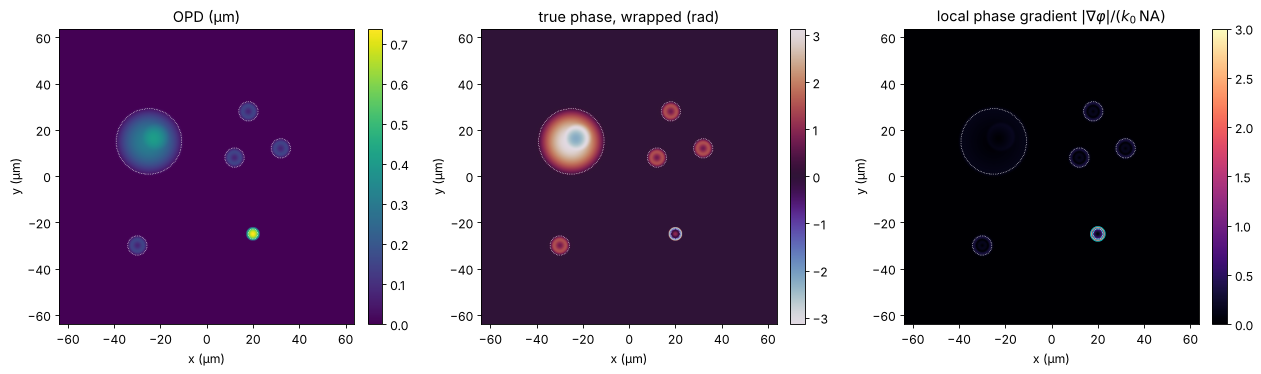

In [2]:
def rho(x0, y0, R):
    return np.hypot(X - x0, Y - y0)/R


def smooth(f, s=0.4):
    return gaussian_filter(f, s/dx, mode="wrap")


def dome(x0, y0, R, h):
    return h*np.clip(1 - rho(x0, y0, R)**2, 0, None)


def evans_fung(x0, y0, D=7.82):
    r = rho(x0, y0, D/2)
    return np.where(r < 1, np.sqrt(np.clip(1 - r**2, 0, None))*(0.81 + 7.83*r**2 - 4.39*r**4), 0.0)


n_cell, n_nucleus, n_rbc = 1.370, 1.390, 1.400
cell_t = smooth(dome(-25, 15, 15, 9.0))
nucleus_t = smooth(dome(-22, 17, 6, 5.0))
rbc_t = smooth(sum(evans_fung(x0, y0) for x0, y0 in [(18, 28), (32, 12), (12, 8), (-30, -30)]), 0.6)
bead_c, R_bead = (20, -25), 3.0
bead_t = smooth(2*R_bead*np.sqrt(np.clip(1 - rho(*bead_c, R_bead)**2, 0, None)), 0.1)


def sample_opd(dn_bead=1.457 - n_m):
    # the nucleus is inside the cell: its excess index over the cytoplasm counts
    return ((n_cell - n_m)*cell_t + (n_nucleus - n_cell)*nucleus_t
            + (n_rbc - n_m)*rbc_t + dn_bead*bead_t)


opd = sample_opd()
k0 = 2*np.pi/wl
phi_true = k0*opd

r_bead = rho(*bead_c, R_bead)
regions = {"cell": cell_t > 1.0, "RBCs": rbc_t > 0.5,
           "bead core": r_bead < 0.7, "bead rim": (r_bead >= 0.7) & (r_bead < 1.1)}
# sample-free pixels, away from the border of the field (see section 3)
background = (opd < 0.002) & (np.abs(X) < L/2 - 5) & (np.abs(Y) < L/2 - 5)
for name, m in regions.items():
    print(f"{name:10s}: phase up to {phi_true[m].max():5.2f} rad = {phi_true[m].max()/(2*np.pi):.2f} waves")

gy, gx = np.gradient(phi_true, dx)
B = k0*NA
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
show(axes[0], opd, "OPD (µm)")
show(axes[1], wrap(phi_true), "true phase, wrapped (rad)", cmap="twilight")
show(axes[2], np.hypot(gx, gy)/B, r"local phase gradient $|\nabla\varphi|/(k_0\,\mathrm{NA})$",
     cmap="magma", vmax=3)
axes[2].contour(x, y, np.hypot(gx, gy)/B, [1.0], colors="c", linewidths=0.8)
for ax in axes:
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
    for name, m in regions.items():
        if name != "bead rim":
            ax.contour(x, y, m, [0.5], colors="w", linewidths=0.6, linestyles=":")
plt.tight_layout()

## 2. The microscope and the off-axis hologram

The objective forms a coherent, band limited image of the sample. The
sample is placed $D = 6$ µm out of focus, as it happens when cells settle
or the stage drifts, and the object wave on the camera carries a
wavefront curvature that the reference wave does not have (a curvature
mismatch between object and reference arms, plus a little astigmatism and
tilt). The camera records the hologram with the reference tilted along
$x$. With 5 µm pixels and $M = 20$, the object space pitch is 0.25 µm, and
the sampling condition of notebook 26, $B \le \pi/(4\Delta x)$, allows an
NA up to $\lambda/(8\Delta x) = 0.32$: the objective uses almost all of
it.

In object space the carrier corresponds to a steep reference angle; on the
camera all angles are divided by the magnification, so the reference
meets the camera at a few degrees. A second hologram without sample
records the aberrations of the instrument alone (background
compensation, "double exposure"). Both holograms are recorded with shot
noise at a mean of 1000 photons per pixel.

reference angle in object space: 42.4° ... 46.4°, using 44.4°; on the camera: 2.68° (fringe period 13.6 µm = 2.7 pixels)


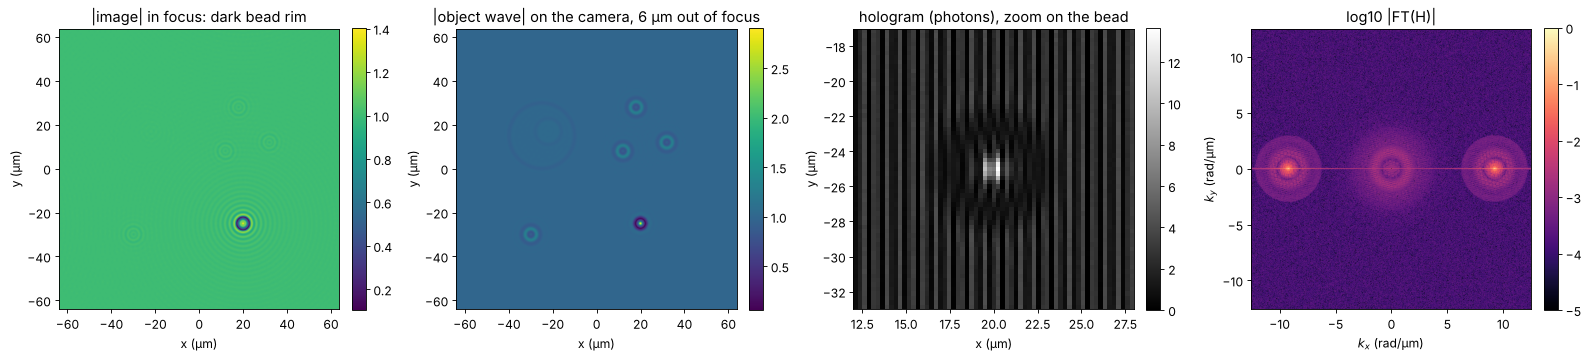

In [3]:
def band_limit(field, wavelength):
    return inv_FT(FT(field)*(K_x**2 + K_y**2 <= (2*np.pi/wavelength*NA)**2))


D = 6.0
camera_aberration = np.exp(1j*(2e-4*(X**2 + Y**2) + 1e-4*(X**2 - Y**2) + 0.02*X))


def object_waves(phase, wavelength):
    # image of the sample (in focus) and object waves of sample and empty field on the camera
    image = band_limit(np.exp(1j*phase), wavelength)
    O = holo.refocus(image, x, y, D, wavelength, **P)*camera_aberration
    return image, O, camera_aberration.copy()


def reference_angle(wavelength):
    return np.mean(holo.off_axis_angle_range(2*np.pi/wavelength*NA, x, y, wavelength, n=n_m))


def record(O, wavelength, photons, rng):
    # off-axis hologram with Poisson noise, `photons` per pixel on average
    H = holo.hologram(O, x, y, wavelength, ref_angle=(reference_angle(wavelength), 0.0), n=n_m)
    if photons is None:
        return H
    scale = photons/np.mean(H)
    return CameraNoiser("poisson", rng=rng)(H*scale)/scale


def reconstruct(H, wavelength):
    return holo.reconstruct_off_axis(H, x, y, wavelength, ref_angle=(reference_angle(wavelength), 0.0),
                                     radius=2*np.pi/wavelength*NA, n=n_m)


image, O, O_bg = object_waves(phi_true, wl)
theta = reference_angle(wl)
theta_min, theta_max = holo.off_axis_angle_range(B, x, y, wl, n=n_m)
theta_camera = np.arcsin(n_m*np.sin(theta)/M)
print(f"reference angle in object space: {np.degrees(theta_min):.1f}° ... {np.degrees(theta_max):.1f}°, "
      f"using {np.degrees(theta):.1f}°; on the camera: {np.degrees(theta_camera):.2f}° "
      f"(fringe period {wl/np.sin(theta_camera):.1f} µm = {wl/np.sin(theta_camera)/pitch:.1f} pixels)")

H = record(O, wl, 1000, rng=1)
H_bg = record(O_bg, wl, 1000, rng=2)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
show(axes[0], np.abs(image), "|image| in focus: dark bead rim")
show(axes[1], np.abs(O), f"|object wave| on the camera, {D:g} µm out of focus")
zoom = (np.abs(x - 20) < 8)
show(axes[2], H[np.ix_(np.abs(y + 25) < 8, zoom)], "hologram (photons), zoom on the bead",
     ext=(12, 28, -33, -17), cmap="gray")
im = show(axes[3], log_spectrum(H), "log10 |FT(H)|", cmap="magma", ext=k_extent, vmin=-5)
axes[3].set_xlabel("$k_x$ (rad/µm)"); axes[3].set_ylabel("$k_y$ (rad/µm)")
for ax in axes[:3]:
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
plt.tight_layout()

## 3. Reconstruction, background compensation and autofocus

`reconstruct_off_axis()` returns the object wave in the camera plane, which
still contains the instrument's aberrations. Multiplying by the complex
conjugate of the sample-free reconstruction removes them, because both
waves share them (this is the `reference_field` of `quantitative_phase()`;
here it is applied before refocusing, since the aberration sits in the
camera plane).

The sample is then out of focus by an unknown distance. `autofocus()`
propagates to a range of planes and evaluates a sharpness metric of the
amplitude. A pure phase object is invisible in focus, so all metrics have a
**minimum** there (`object_type="phase"`; notebook 26). The search runs on
a window around the cells, away from the bead whose rim stays dark in every
plane.

rms phase error (rad)
hologram, wrapped                 cell:  0.0121   RBCs:  0.0242   bead core:  0.2719   bead rim:  1.0085   


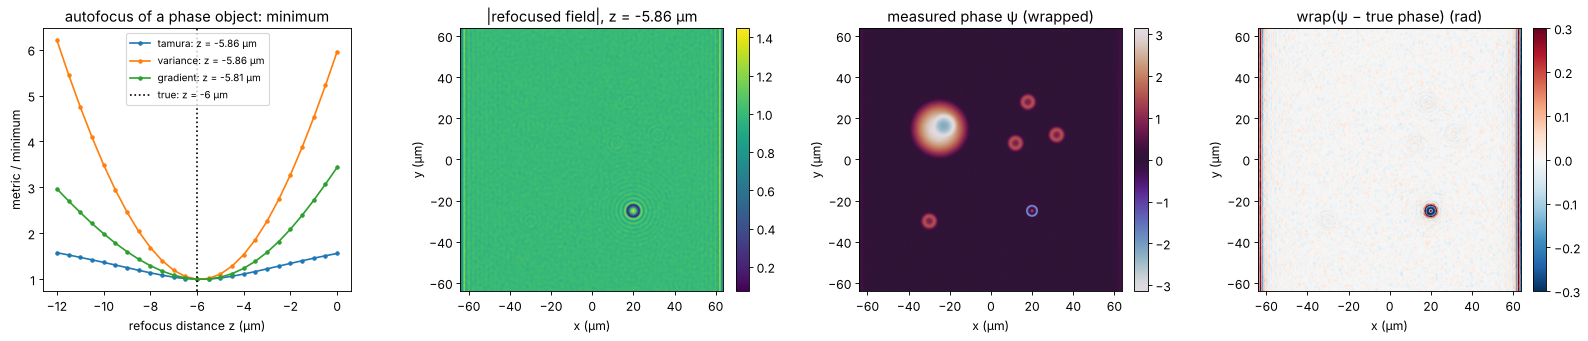

In [4]:
O_rec = reconstruct(H, wl)
O_rec_bg = reconstruct(H_bg, wl)
O_c = O_rec*np.conj(O_rec_bg)/np.abs(O_rec_bg)       # background compensated

z_range = np.linspace(-12, 0, 25)
cells_window = (np.abs(X + 5) < 45) & (Y > -10)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for metric in ("tamura", "variance", "gradient"):
    z_best, values = holo.autofocus(O_c, x, y, z_range, wl, metric=metric, object_type="phase",
                                    mask=cells_window, **P)
    axes[0].plot(z_range, values/values.min(), "o-", ms=3, label=f"{metric}: z = {z_best:.2f} µm")
z_focus, _ = holo.autofocus(O_c, x, y, z_range, wl, metric="tamura", object_type="phase",
                            mask=cells_window, **P)
axes[0].axvline(-D, color="k", ls=":", label=f"true: z = {-D:g} µm")
axes[0].set_xlabel("refocus distance z (µm)"); axes[0].set_ylabel("metric / minimum")
axes[0].set_title("autofocus of a phase object: minimum"); axes[0].legend(fontsize=9)

U = holo.refocus(O_c, x, y, z_focus, wl, **P)
psi = np.angle(U*np.exp(-1j*np.angle(np.mean(U[background]))))   # piston: background at 0
show(axes[1], np.abs(U), f"|refocused field|, z = {z_focus:.2f} µm")
show(axes[2], psi, "measured phase ψ (wrapped)", cmap="twilight")
show(axes[3], wrap(psi - phi_true), "wrap(ψ − true phase) (rad)", cmap="RdBu_r", vmin=-0.3, vmax=0.3)
for ax in axes[1:]:
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
plt.tight_layout()


def rms_errors(phase, wrapped=False):
    e = phase - phi_true
    e = wrap(e) if wrapped else e - np.nanmedian(e[background])
    return {name: np.sqrt(np.nanmean(e[m]**2)) for name, m in regions.items()}


def print_errors(label, phase, wrapped=False):
    print(f"{label:34s}" + "".join(f"{name}: {v:7.4f}   " for name, v in rms_errors(phase, wrapped).items()))


print("rms phase error (rad)")
print_errors("hologram, wrapped", psi, wrapped=True)

The autofocus finds the defocus to about 0.1 µm, a small fraction of the
depth of field ($n_m\lambda/\mathrm{NA}^2 \approx 9$ µm). The wrapped
phase agrees with the truth to a few milliradians on the cell (the shot
noise of 1000 photons per pixel) and to a few hundredths of a radian on
the red blood cells, whose rim is slightly finer than the objective
resolves. In the bead core the error is a few tenths of a radian: the core
is resolved, but the light refracted at the rim is missing from the image,
and its diffraction reaches into the core. At the rim the measured phase
has nothing to do with the truth any more. The stripes at the left and
right border of the field are the ringing of the sideband filter at the
edge of the (non-periodic) hologram; the border is left out of all
comparisons.

## 4. Unwrapping the hologram phase

`quantitative_phase()` unwraps with the quality guided algorithm (Herráez,
amplitude as quality) or with least squares (Ghiglia and Romero), see
notebook 22. On the cells both recover the true phase exactly, wraps and
all: neighbouring pixels differ by less than π everywhere, since the
off-axis sampling condition keeps the phase gradient below $B < \pi/(4\Delta x)$.

The bead is different. Across its rim the true phase rises by several
radians over less than a resolution element, the field there is dark and
its phase is garbage. Both unwrappers cross the rim with a wrong number of
wraps and put the core off by a multiple of $2\pi$, although the wrapped
phase in the core is right to 0.3 rad. Note that the map has no residues:
an unresolved step is not detected as an inconsistency, it simply gets the
wrong height. No algorithm working on a single wrapped phase can do better,
because the information is not in the data.

residues in the measured phase: 0
quality guided                    cell:  0.0121   RBCs:  0.0242   bead core:  6.4939   bead rim:  4.4555   
least squares                     cell:  0.0121   RBCs:  0.0242   bead core:  6.4939   bead rim:  4.4555   
bead core off by -1.04 × 2π


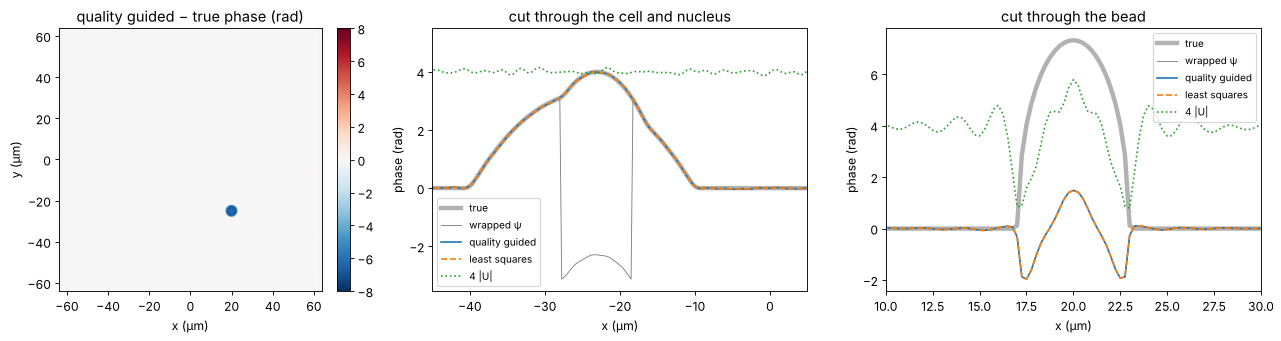

In [5]:
phase_quality = holo.quantitative_phase(U, x, y, unwrap="quality", tilt_mask=background)
phase_ls = holo.quantitative_phase(U, x, y, unwrap="ls", tilt_mask=background)
print(f"residues in the measured phase: {int(np.abs(residues(psi)).sum())}")
print_errors("quality guided", phase_quality)
print_errors("least squares", phase_ls)
off = (phase_quality - phi_true)[regions["bead core"]]
print(f"bead core off by {np.median(off - np.median((phase_quality - phi_true)[background]))/(2*np.pi):.2f} × 2π")

row = np.argmin(np.abs(y - bead_c[1]))
row_cell = np.argmin(np.abs(y - 15))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
show(axes[0], phase_quality - phi_true, "quality guided − true phase (rad)", cmap="RdBu_r", vmin=-8, vmax=8)
axes[0].set_xlabel("x (µm)"); axes[0].set_ylabel("y (µm)")
for ax, r, xlim, title in [(axes[1], row_cell, (-45, 5), "cut through the cell and nucleus"),
                            (axes[2], row, (10, 30), "cut through the bead")]:
    ax.plot(x, phi_true[r], "k", lw=4, alpha=0.3, label="true")
    ax.plot(x, psi[r], "C7", lw=0.8, label="wrapped ψ")
    ax.plot(x, phase_quality[r], "C0", label="quality guided")
    ax.plot(x, phase_ls[r], "C1--", label="least squares")
    ax.plot(x, np.abs(U[r])*4, "C2:", label="4 |U|")
    ax.set_xlim(*xlim); ax.set_xlabel("x (µm)"); ax.set_ylabel("phase (rad)"); ax.set_title(title)
    ax.legend(fontsize=9)
plt.tight_layout()

## 5. The transport of intensity equation

The TIE (notebook 29) relates the axial change of intensity to the phase,

$$k\,\frac{\partial I}{\partial z} = -\nabla_\perp\cdot\left(I\,\nabla_\perp\varphi\right),$$

with $k = n_m k_0$ in the medium. Two images at $\pm\Delta z$ give
$\partial I/\partial z$, and `TIE.solve_tie()` solves for $\varphi$ with FFT
Poisson solvers. The result is **unwrapped by construction**: it is the
solution of a differential equation, not an angle. Two ways to get the
images:

- **numerical defocus of the hologram**: refocus the reconstructed field to
  $\pm\Delta z$ and take $|U|^2$. This needs no extra measurement and adds
  nothing the hologram does not know, but it gives a phase without the
  $2\pi$ ambiguity;
- **a bright field focus stack**: move the stage by $\pm\Delta z$ and take
  intensity images, with the same objective but without reference arm,
  i.e. with any microscope. Without interference, nothing limits the
  exposure but the full well, and frames can be averaged at leisure: the
  stack is computed at 1000 and at 10⁴ photons per pixel.

The choice of $\Delta z$ is a compromise: small steps amplify the noise in
the difference quotient, large steps violate the linearisation of the TIE
and blur fine detail. For the numerically defocused images the noise is the
same in both planes (one field), so it partly cancels in the difference.

TIE from the hologram, Δz = 1 µm  cell:  0.0567   RBCs:  0.0555   bead core:  4.6840   bead rim:  2.9614   
TIE bright field 10⁴, Δz = 4 µm   cell:  0.0364   RBCs:  0.0432   bead core:  4.6202   bead rim:  2.8807   


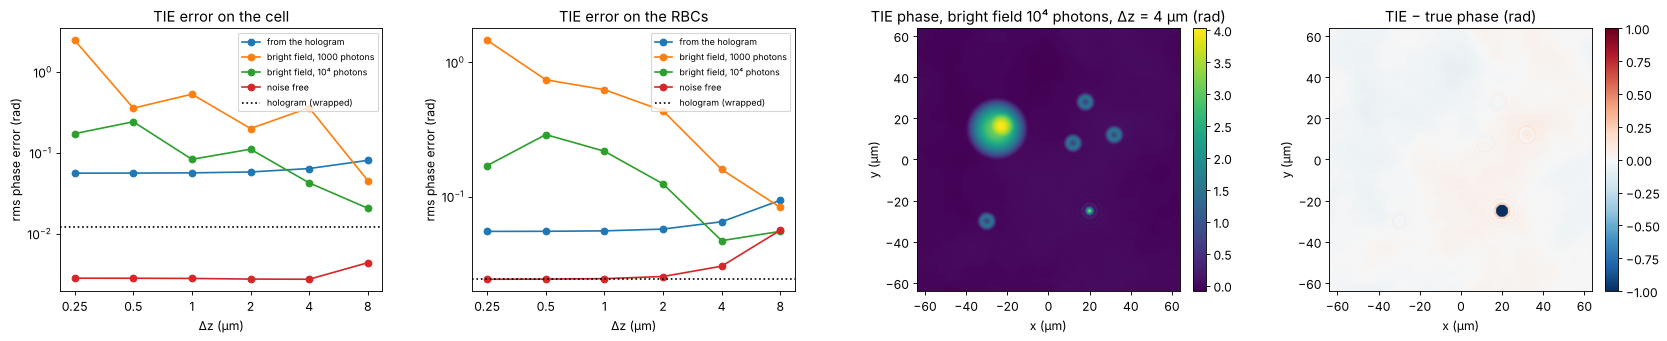

In [6]:
k_m = n_m*k0
rng_bf = np.random.default_rng(3)
bright_field = CameraNoiser("poisson", rng=rng_bf)


def tie_phase(intensity_at, dz, I0):
    dI_dz = (intensity_at(dz) - intensity_at(-dz))/(2*dz)
    phase = TIE.solve_tie(np.maximum(gaussian_filter(I0, 2), 0.05), dI_dz, x, y, wl/n_m, 0.0)
    return phase - np.median(phase[background])


def hologram_intensity(z):
    return np.abs(holo.refocus(U, x, y, z, wl, **P))**2


def bright_field_intensity(z, photons):
    I = np.abs(holo.refocus(image, x, y, z, wl, **P))**2
    return bright_field(I*photons)/photons


def noise_free_intensity(z):
    return np.abs(holo.refocus(image, x, y, z, wl, **P))**2


dzs = np.array([0.25, 0.5, 1.0, 2.0, 4.0, 8.0])
errors = {"from the hologram": [], "bright field, 1000 photons": [], "bright field, 10⁴ photons": [],
          "noise free": []}
for dz in dzs:
    errors["from the hologram"].append(rms_errors(tie_phase(hologram_intensity, dz, np.abs(U)**2)))
    for photons in (1000, 10000):
        errors[f"bright field, {photons if photons == 1000 else '10⁴'} photons"].append(rms_errors(
            tie_phase(lambda z: bright_field_intensity(z, photons), dz, bright_field_intensity(0.0, photons))))
    errors["noise free"].append(rms_errors(tie_phase(noise_free_intensity, dz, np.abs(image)**2)))

phase_tie_holo = tie_phase(hologram_intensity, 1.0, np.abs(U)**2)
phase_tie_bf = tie_phase(lambda z: bright_field_intensity(z, 10000), 4.0, bright_field_intensity(0.0, 10000))
print_errors("TIE from the hologram, Δz = 1 µm", phase_tie_holo)
print_errors("TIE bright field 10⁴, Δz = 4 µm", phase_tie_bf)

fig, axes = plt.subplots(1, 4, figsize=(21, 4.4))
for i, name in enumerate(("cell", "RBCs")):
    for j, (label, errs) in enumerate(errors.items()):
        axes[i].loglog(dzs, [e[name] for e in errs], "o-", color=f"C{j}", label=label)
    axes[i].axhline(rms_errors(psi, wrapped=True)[name], color="k", ls=":", label="hologram (wrapped)")
    axes[i].set_xticks(dzs, [f"{dz:g}" for dz in dzs], minor=False)
    axes[i].minorticks_off()
    axes[i].set_xlabel("Δz (µm)"); axes[i].set_ylabel("rms phase error (rad)")
    axes[i].set_title(f"TIE error on the {name}"); axes[i].legend(fontsize=8)
show(axes[2], phase_tie_bf, "TIE phase, bright field 10⁴ photons, Δz = 4 µm (rad)")
show(axes[3], phase_tie_bf - phi_true, "TIE − true phase (rad)", cmap="RdBu_r", vmin=-1, vmax=1)
for ax in axes[2:]:
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
plt.tight_layout()

The TIE gets the unwrapped phase of the cell right to about 0.05 rad,
including the nucleus and all the wraps. It is several times less precise
than the hologram, and its error is low frequency: the Poisson solver
integrates the noise and any flux that is not accounted for. The largest
such flux is the light the bead throws outside the aperture: the TIE
assumes that intensity is conserved, so the bead is badly underestimated,
and a halo of error spreads around it.

The curves show the compromise in $\Delta z$. Without noise, the TIE is
accurate to a few milliradians on the cell for all steps up to several
micrometres (the depth of field is $n_m\lambda/\mathrm{NA}^2 \approx 9$ µm);
the red blood cells, with finer detail, see the finite difference bias
first. The TIE from the hologram has a constant error: the noise of the
reconstructed field itself, the same in both planes, integrated by the
solver. The bright field stack has independent noise in each image, which
the difference quotient amplifies by $1/\Delta z$: below a micrometre the
TIE drowns in noise, and even at 10⁴ photons it needs steps of a few
micrometres.

## 6. Low light: hologram unwrapped with the TIE as reference

At low exposure the hologram phase gets noisy, the noise creates residues
(pairs of phase vortices), and path following unwrappers start to make
$2\pi$ errors that spread over whole patches. The TIE phase does not care
about residues; it is smooth and, on the cells, within ±π of the truth.
`unwrap_with_reference()` uses it to pick the multiple of $2\pi$ for every
pixel separately,

$$\varphi = \psi + 2\pi\,\mathrm{round}\!\left(\frac{\varphi_\text{TIE} - \psi}{2\pi}\right),$$

which keeps the resolution and the noise level of the hologram but takes
the wrap count from the TIE. The reference is the bright field TIE of
section 5 (10⁴ photons, $\Delta z = 4$ µm): it costs no reference arm and can be exposed as
long as needed, so it is a natural partner of a low light hologram. (The
TIE of the noisy hologram itself does not help here: it inherits the
hologram's noise.) The photon numbers are per camera pixel; the sideband
filter collects the light of all pixels within a resolution element, so
the phase noise stays moderate down to well below one photon per pixel.
The table counts the pixels of the cells (cell and red blood cells) with
an error larger than π, i.e. with a wrong wrap.

  1000 photons: wrapped noise on the cell 0.015 rad,     0 residues; wrong wraps: quality guided  0.00 %, least squares  0.00 %, TIE guided  0.00 %


     1 photons: wrapped noise on the cell 0.306 rad,    18 residues; wrong wraps: quality guided  0.00 %, least squares  0.00 %, TIE guided  0.00 %


   0.2 photons: wrapped noise on the cell 0.789 rad,  1648 residues; wrong wraps: quality guided  0.33 %, least squares  0.10 %, TIE guided  0.01 %


   0.1 photons: wrapped noise on the cell 1.069 rad,  3142 residues; wrong wraps: quality guided  1.15 %, least squares  0.61 %, TIE guided  0.05 %


  0.05 photons: wrapped noise on the cell 1.277 rad,  4368 residues; wrong wraps: quality guided 31.59 %, least squares 14.66 %, TIE guided  0.12 %


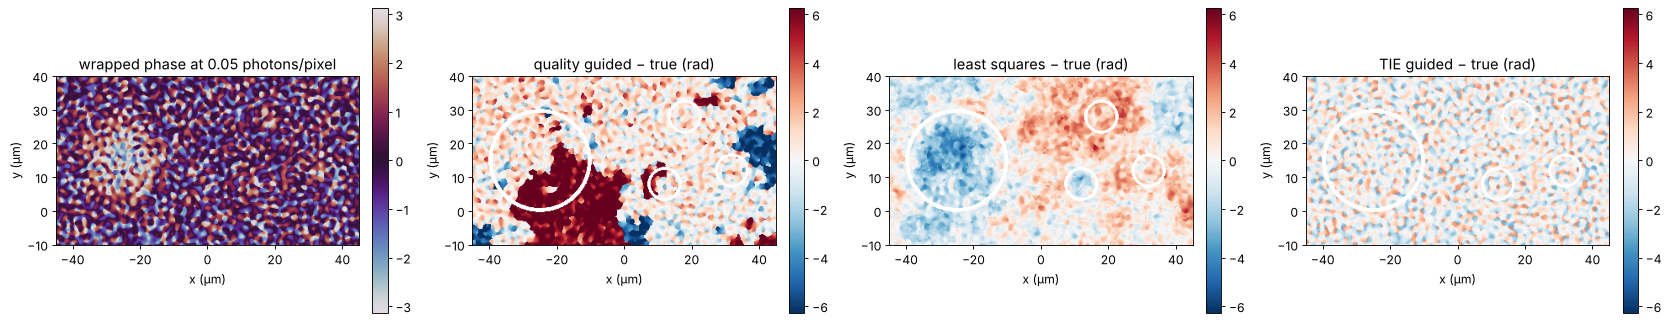

In [7]:
cells_mask = regions["cell"] | regions["RBCs"]


def wrong_wraps(phase):
    e = phase - phi_true
    e = e - np.nanmedian(e[background])
    return np.mean(np.abs(e[cells_mask]) > np.pi)


photon_levels = [1000, 1, 0.2, 0.1, 0.05]
results = {}
for photons in photon_levels:
    H_low = record(O, wl, photons, rng=10)
    H_low_bg = record(O_bg, wl, 1000, rng=11)     # the background can be averaged over many frames
    O_low = reconstruct(H_low, wl)*np.conj(reconstruct(H_low_bg, wl))
    U_low = holo.refocus(O_low/np.abs(O_low).mean(), x, y, z_focus, wl, **P)
    psi_low = np.angle(U_low*np.exp(-1j*np.angle(np.mean(U_low[background]))))
    results[photons] = dict(
        psi=psi_low,
        quality=holo.quantitative_phase(U_low, x, y, unwrap="quality", tilt_mask=background),
        ls=holo.quantitative_phase(U_low, x, y, unwrap="ls", tilt_mask=background),
        guided=unwrap_with_reference(psi_low, phase_tie_bf))
    r = results[photons]
    print(f"{photons:6g} photons: wrapped noise on the cell {rms_errors(psi_low, True)['cell']:.3f} rad, "
          f"{int(np.abs(residues(psi_low)).sum()):5d} residues; wrong wraps: "
          f"quality guided {100*wrong_wraps(r['quality']):5.2f} %, least squares {100*wrong_wraps(r['ls']):5.2f} %, "
          f"TIE guided {100*wrong_wraps(r['guided']):5.2f} %")

photons = 0.05
r = results[photons]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.4))
show(axes[0], r["psi"], f"wrapped phase at {photons:g} photons/pixel", cmap="twilight")
for ax, key, title in [(axes[1], "quality", "quality guided − true"), (axes[2], "ls", "least squares − true"),
                       (axes[3], "guided", "TIE guided − true")]:
    show(ax, np.where(background | cells_mask, r[key] - phi_true, np.nan), title + " (rad)",
         cmap="RdBu_r", vmin=-2*np.pi, vmax=2*np.pi)
for ax in axes:
    ax.set_xlim(-45, 45); ax.set_ylim(-10, 40); ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
plt.tight_layout()

Down to about one photon per pixel all unwrappers agree, and even with
thousands of residues at 0.2 photons only a few pixels in a thousand go
wrong: the quality map steers the path around the residues. At the lowest
exposure the quality guided unwrapper places whole patches a wrap
off; least squares does not jump, but smooths the phase and pulls it
towards zero where residues pile up (it is not congruent with the data).
The TIE guided result stays at the hologram's own noise level: the few
pixels left with an error above π are noise spikes, not wrong wraps. Only
where the TIE is off by more than π, as on the bead, does the reference
fail.

## 7. Two-wavelength holography for the bead

The bead core cannot be connected to its surroundings through the dark rim,
and the TIE cannot see it either. A second hologram at another wavelength
helps: both phases belong to the same OPD, and their difference is the
phase at the **synthetic wavelength**

$$\Lambda = \frac{\lambda_1\lambda_2}{|\lambda_1 - \lambda_2|},$$

which is unambiguous for $|\mathrm{OPD}| < \Lambda/2$ in every pixel by
itself, no path needed (Gass, Dakoff and Kim, Opt. Lett. 28, 1141 (2003)).
With a 785 nm diode next to the HeNe, $\Lambda = 3.3$ µm, more than four
times the bead's OPD. The synthetic phase has $\Lambda/\lambda$ times the
noise of the single phases; `unwrap_two_wavelength()` therefore uses it only
as a reference to unwrap the two single wavelength phases and averages
them (hierarchical unwrapping), which is exact as long as the coarse OPD
is within $\pm\lambda/2$.

The sample is not quite the same at the two wavelengths: silica and water
disperse differently (with `materials.abbe_dispersion()`: fused silica
$n_d = 1.4585$, $V_d = 67.8$; water $n_d = 1.333$, $V_d = 55.8$), so the
bead's OPD differs by a few nanometres between the wavelengths. The
synthetic wavelength amplifies this by $\Lambda/\lambda$ as well, which is
the main systematic error of the method.

synthetic wavelength 3.269 µm, Λ/λ1 = 5.2; bead OPD 0.736 µm
dispersion: bead OPD at 633 nm 0.7495 µm, at 785 nm 0.7473 µm


synthetic wavelength (coarse)     cell:  0.0949   RBCs:  0.1536   bead core:  0.8934   bead rim:  5.1181   
two wavelengths, refined          cell:  0.0097   RBCs:  0.0267   bead core:  0.3721   bead rim:  5.1692   
two wavelengths, dispersive       cell:  0.0114   RBCs:  0.0267   bead core:  0.3788   bead rim:  4.4087   


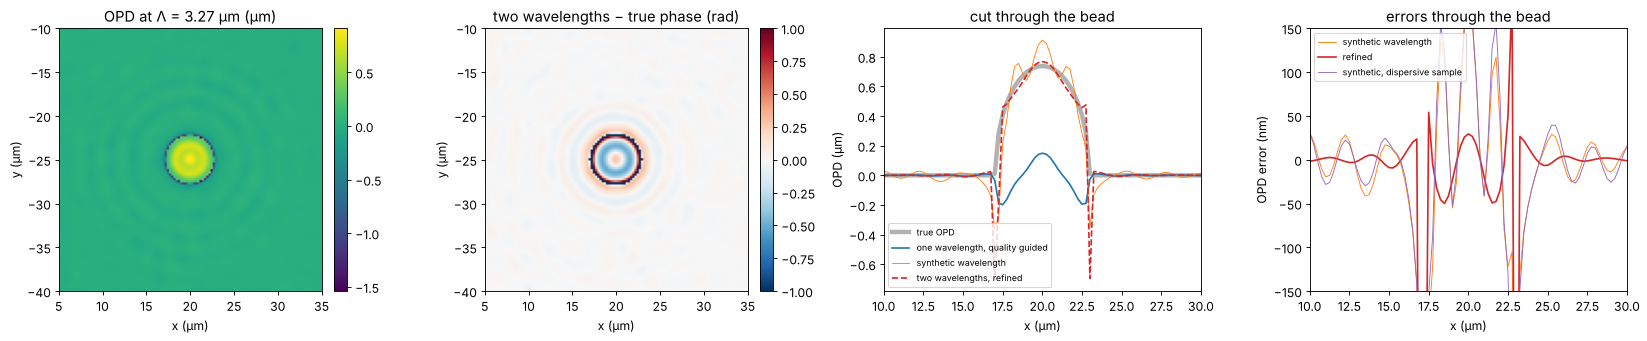

In [8]:
wl2 = 0.785
Lambda = synthetic_wavelength(wl, wl2)


def n_disp(n_d, V_d, wavelength):
    return abbe_dispersion(wavelength*1e3, n_d, V_d)


def measured_phase(wavelength, opd_map, photons=1000, seed=20):
    phase = 2*np.pi/wavelength*opd_map
    image_, O_, O_bg_ = object_waves(phase, wavelength)
    O_r = (reconstruct(record(O_, wavelength, photons, rng=seed), wavelength)
           *np.conj(reconstruct(record(O_bg_, wavelength, photons, rng=seed + 1), wavelength)))
    U_ = holo.refocus(O_r/np.abs(O_r).mean(), x, y, z_focus, wavelength, **P)
    return np.angle(U_*np.exp(-1j*np.angle(np.mean(U_[background]))))


# without dispersion: the same OPD at both wavelengths
psi2 = measured_phase(wl2, opd)
opd_coarse = unwrap_two_wavelength(psi, psi2, wl, wl2, refine=False)
opd_2wl = unwrap_two_wavelength(psi, psi2, wl, wl2)

# with dispersion of the bead against the medium (the cells disperse like water)
opd_at = {w: sample_opd(n_disp(1.4585, 67.8, w) - n_disp(1.333, 55.8, w)) for w in (wl, wl2)}
bead_peak = regions["bead core"] & (r_bead < 0.1)
print(f"synthetic wavelength {Lambda:.3f} µm, Λ/λ1 = {Lambda/wl:.1f}; bead OPD {opd[bead_peak].mean():.3f} µm")
print(f"dispersion: bead OPD at {wl*1e3:.0f} nm {opd_at[wl][bead_peak].mean():.4f} µm, "
      f"at {wl2*1e3:.0f} nm {opd_at[wl2][bead_peak].mean():.4f} µm")
psi1_d, psi2_d = measured_phase(wl, opd_at[wl], seed=30), measured_phase(wl2, opd_at[wl2], seed=32)
opd_2wl_d = unwrap_two_wavelength(psi1_d, psi2_d, wl, wl2)
opd_coarse_d = unwrap_two_wavelength(psi1_d, psi2_d, wl, wl2, refine=False)

print_errors("synthetic wavelength (coarse)", k0*opd_coarse)
print_errors("two wavelengths, refined", k0*opd_2wl)
print_errors("two wavelengths, dispersive", k0*opd_2wl_d - k0*(opd_at[wl] - opd))

fig, axes = plt.subplots(1, 4, figsize=(21, 4.4))
show(axes[0], np.where(background | (r_bead < 1.3), opd_coarse, np.nan), f"OPD at Λ = {Lambda:.2f} µm (µm)")
show(axes[1], k0*opd_2wl - phi_true, "two wavelengths − true phase (rad)", cmap="RdBu_r", vmin=-1, vmax=1)
for ax in axes[:2]:
    ax.set_xlim(5, 35); ax.set_ylim(-40, -10); ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
ax = axes[2]
ax.plot(x, opd[row], "k", lw=4, alpha=0.3, label="true OPD")
ax.plot(x, phase_quality[row]/k0, "C0", label="one wavelength, quality guided")
ax.plot(x, opd_coarse[row], "C1", lw=0.8, label="synthetic wavelength")
ax.plot(x, opd_2wl[row], "C3--", label="two wavelengths, refined")
ax.set_xlim(10, 30); ax.set_xlabel("x (µm)"); ax.set_ylabel("OPD (µm)"); ax.legend(fontsize=8)
ax.set_title("cut through the bead")
ax = axes[3]
ax.plot(x, (opd_coarse - opd)[row]*1e3, "C1", lw=0.8, label="synthetic wavelength")
ax.plot(x, (opd_2wl - opd)[row]*1e3, "C3", label="refined")
ax.plot(x, (opd_coarse_d - opd_at[wl])[row]*1e3, "C4", lw=0.8, label="synthetic, dispersive sample")
ax.set_xlim(10, 30); ax.set_ylim(-150, 150); ax.set_xlabel("x (µm)"); ax.set_ylabel("OPD error (nm)")
ax.set_title("errors through the bead"); ax.legend(fontsize=8)
plt.tight_layout()

The bead core comes out at the right height: the remaining error of a few
tenths of a radian is the one the wrapped phase already had (the missing
rim light), not a wrap. At the rim the method fails like all others, since
the field there carries no usable phase at either wavelength. Dispersion
shifts the synthetic OPD of the bead by $\Lambda/\lambda$ times the OPD
difference between the wavelengths; here this stays well below
$\lambda/2$, so the refined result is still congruent with the 633 nm
phase. For strongly dispersive samples or closer wavelengths (larger
$\Lambda$), this limits the method.

## 8. Summary

The rms phase errors of all methods against the true phase, in the four
regions (radians at 633 nm, 1000 photons per pixel unless stated):

In [9]:
rows = [("hologram, wrapped (reference only)", psi, True),
        ("hologram + quality guided unwrapping", phase_quality, False),
        ("hologram + least squares unwrapping", phase_ls, False),
        ("TIE from the hologram (Δz = 1 µm)", phase_tie_holo, False),
        ("TIE, bright field 10⁴ photons (Δz = 4 µm)", phase_tie_bf, False),
        ("hologram at 0.05 photons, quality guided", results[0.05]["quality"], False),
        ("hologram at 0.05 photons, least squares", results[0.05]["ls"], False),
        ("hologram at 0.05 photons, TIE guided", results[0.05]["guided"], False),
        ("two wavelengths (633 + 785 nm)", k0*opd_2wl, False)]
print(f"{'method':42s}" + "".join(f"{name:>11s}" for name in regions))
for label, phase, wrapped in rows:
    print(f"{label:42s}" + "".join(f"{v:11.3f}" for v in rms_errors(phase, wrapped).values()))
print(f"\nrun time {time.time() - t_start:.0f} s")

method                                           cell       RBCs  bead core   bead rim
hologram, wrapped (reference only)              0.012      0.024      0.272      1.008
hologram + quality guided unwrapping            0.012      0.024      6.494      4.455
hologram + least squares unwrapping             0.012      0.024      6.494      4.455
TIE from the hologram (Δz = 1 µm)               0.057      0.055      4.684      2.961
TIE, bright field 10⁴ photons (Δz = 4 µm)       0.036      0.043      4.620      2.881
hologram at 0.05 photons, quality guided        4.325      1.888      5.999      3.826
hologram at 0.05 photons, least squares         2.340      1.501      5.004      2.805
hologram at 0.05 photons, TIE guided            1.277      1.172      5.599      3.492
two wavelengths (633 + 785 nm)                  0.010      0.027      0.372      5.169

run time 23 s


- **Off-axis DHM** measures the phase of smooth cells to the shot noise
  limit (milliradians, i.e. sub-nanometre OPD), after numerical refocusing
  and background compensation from a sample-free hologram. Where the sample
  is resolved, the sampling condition of the off-axis geometry also keeps
  the phase gradient below π per pixel, and both unwrappers are exact.
- **Unresolved steep edges** (the bead rim) leave the hologram with no phase
  information there; a single wavelength cannot tell how many waves the
  edge climbs, and the unwrapped core is off by multiples of 2π without
  any residue to warn.
- **The TIE** gives an unwrapped phase from intensities alone, with a
  bright field microscope or from the hologram itself, about ten times
  less precise and biased wherever light leaves the aperture. Its strength
  is robustness: as the reference of `unwrap_with_reference()` it removes
  all wrap errors of a noisy low light hologram while keeping the
  hologram's resolution.
- **Two wavelengths** unwrap pixel by pixel within $\pm\Lambda/2$ and
  recover the bead; the price is a second laser and a sensitivity to
  dispersion that grows with $\Lambda/\lambda$.